In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## fig1

**Figure 1: AIME 2024 scores of DAPO on the Qwen2.5-32B base model over training.** The dashed grey line marks DeepSeek-R1-Zero-Qwen-32B, which reaches 47 after 10k steps. DAPO's avg@32 reaches 49.6 at 5.3k steps, surpassing it with about half the training steps.

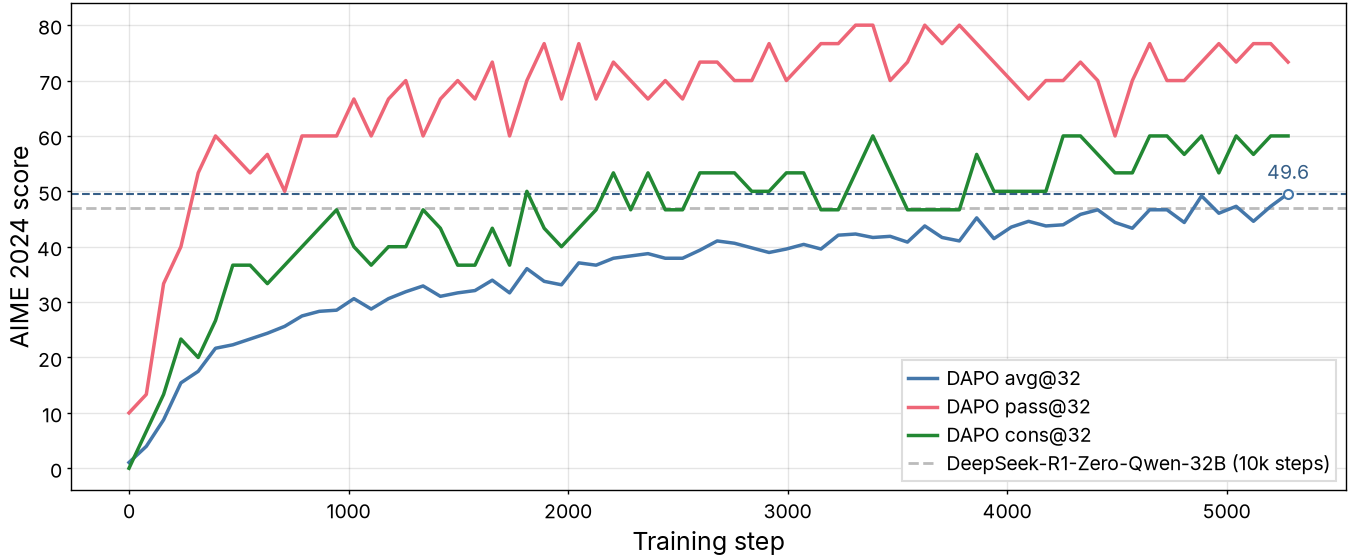

In [2]:
data = json.load(open("../dapo.json"))["fig1"]

fig, ax = plt.subplots(figsize=(6.75, 2.5))
for name, color in [("DAPO avg@32", colors["series-1"]), ("DAPO pass@32", colors["series-2"]), ("DAPO cons@32", colors["series-3"])]:
    ax.plot(data[name]["step"], data[name]["value"], color=color, label=name)
ax.axhline(47, color="#BBBBBB", linestyle="--", linewidth=1, zorder=1, label="DeepSeek-R1-Zero-Qwen-32B (10k steps)")
avg = data["DAPO avg@32"]
mark_value(ax, avg["step"][-1], avg["value"][-1], "49.6", colors["series-1"])
ax.set_xlabel("Training step")
ax.set_ylabel("AIME 2024 score")
ax.legend(loc="lower right")

fit_height(fig, ax, aspect=0.382)
fig.savefig("fig1.pdf")
fig.savefig("fig1.png")
plt.show()

## fig2

**Figure 2: AIME accuracy with and without Clip-Higher.** Dashed lines mark each run's best avg@32. Clip-Higher lifts the best AIME avg@32 from 0.269 to 0.406.

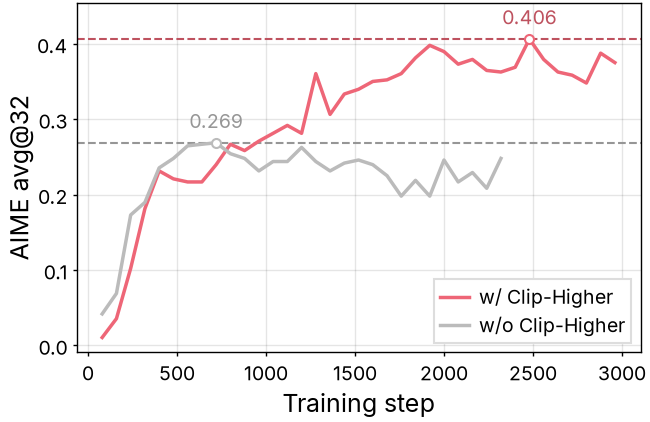

In [3]:
data = json.load(open("../dapo.json"))

fig, ax = plt.subplots(figsize=(3.25, 2))
for name, color in [("w/ Clip-Higher", colors["series-2"]), ("w/o Clip-Higher", colors["neutral"])]:
    acc = data["fig2a"][name]
    ax.plot(acc["step"], acc["value"], color=color, label=name)
    best = max(acc["value"])
    mark_value(ax, acc["step"][acc["value"].index(best)], best, f"{best:.3f}", color)

ax.set_xlabel("Training step")
ax.set_ylabel("AIME avg@32")
ax.legend(loc="lower right")

fit_height(fig, ax, aspect=0.618)
fig.savefig("fig2.pdf")
fig.savefig("fig2.png")
plt.show()

## fig3

**Figure 3: Mean up-clipped probability and proportion of samples with an accuracy of 1 during training.** The left panel shows the mean probability of tokens clipped by the upper clip bound and the right panel the proportion of sampled prompts whose responses all reach accuracy 1; curves are smoothed with a moving average over 5% of the steps; faint lines show raw values. The up-clipped tokens have low probability (smoothed mean below 0.26), while the share of samples with accuracy 1 rises from 0.02 to 0.57.

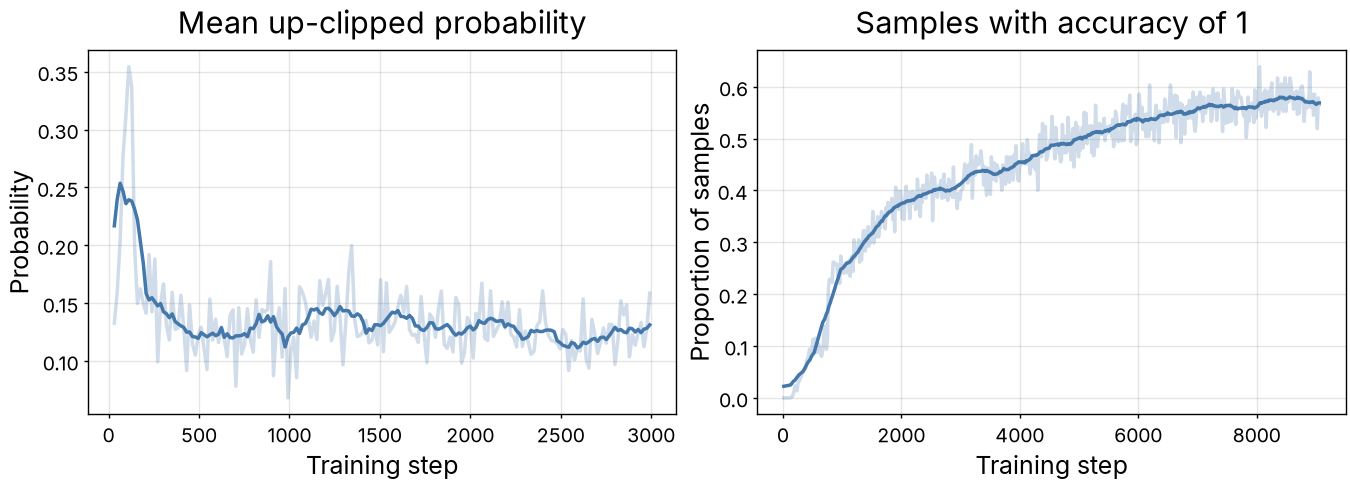

In [4]:
data = json.load(open("../dapo.json"))

fig, axes = plt.subplots(1, 2, figsize=(6.75, 2.5))
for ax, key in zip(axes, ["fig3a", "fig3b"]):
    ax.plot(data[key]["step"], data[key]["value"], color=colors["series-1"], alpha=0.25)
    ax.plot(data[key]["step"], smooth(data[key]["value"]), color=colors["series-1"])
    ax.set_xlabel("Training step")

axes[0].set_title("Mean up-clipped probability")
axes[0].set_ylabel("Probability")
axes[1].set_title("Samples with accuracy of 1")
axes[1].set_ylabel("Proportion of samples")

fit_height(fig, axes, aspect=0.618)
fig.savefig("fig3.pdf")
fig.savefig("fig3.png")
plt.show()

## fig4

**Figure 4: Entropy and response length with and without the token-level policy gradient loss.** The left panel shows the entropy of the actor model's generation probabilities and the right panel the average response length in tokens; curves are smoothed with a moving average over 5% of the steps; faint lines show raw values. Without the token-level loss, entropy climbs to 2.99 and response length spikes to 4.33k tokens before falling, while with it entropy stays below 0.98 and length rises gradually.

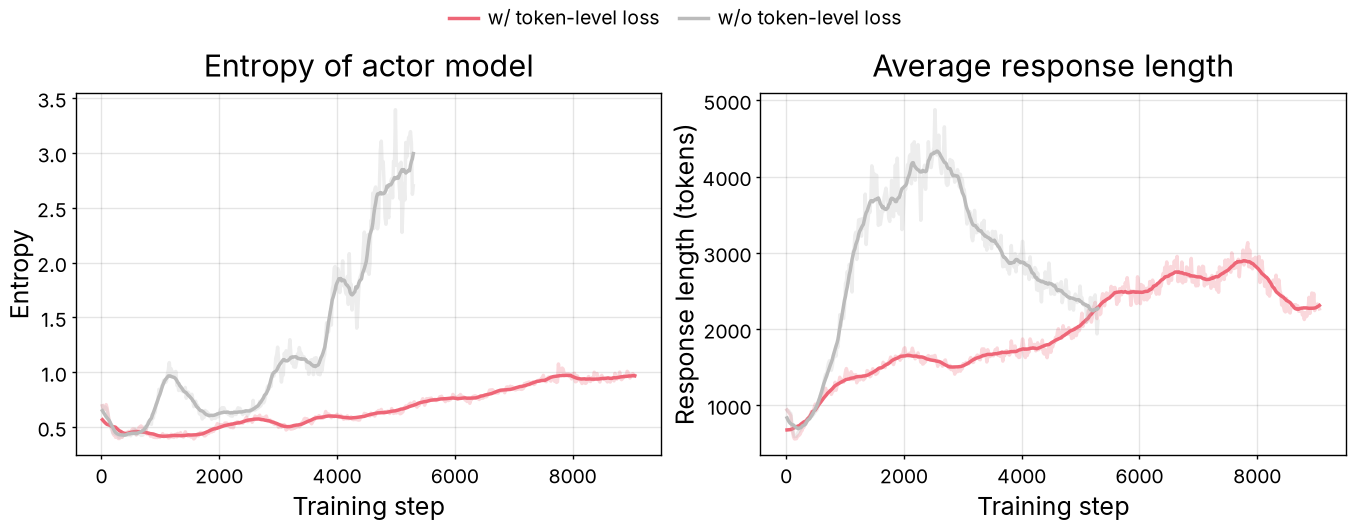

In [5]:
data = json.load(open("../dapo.json"))

fig, axes = plt.subplots(1, 2, figsize=(6.75, 2.5))
for name, color in [("w/ token-level loss", colors["series-2"]), ("w/o token-level loss", colors["neutral"])]:
    for ax, key in zip(axes, ["fig4a", "fig4b"]):
        ax.plot(data[key][name]["step"], data[key][name]["value"], color=color, alpha=0.25)
        ax.plot(data[key][name]["step"], smooth(data[key][name]["value"]), color=color, label=name if key == "fig4a" else None)

axes[0].set_title("Entropy of actor model")
axes[0].set_ylabel("Entropy")
axes[1].set_title("Average response length")
axes[1].set_ylabel("Response length (tokens)")
for ax in axes:
    ax.set_xlabel("Training step")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside upper center", ncol=2, frameon=False, borderaxespad=0)

fit_height(fig, axes, aspect=0.618)
fig.savefig("fig4.pdf")
fig.savefig("fig4.png")
plt.show()

## fig5

**Figure 5: AIME accuracy and actor entropy with and without overlong filtering.** The left panel shows avg@32 on AIME, with dashed lines at each run's best score; the right panel shows the entropy of the actor model, smoothed with a moving average over 5% of the steps; faint lines show raw values. Overlong filtering raises the best AIME avg@32 from 0.302 to 0.358, while without it entropy surges to 3.25.

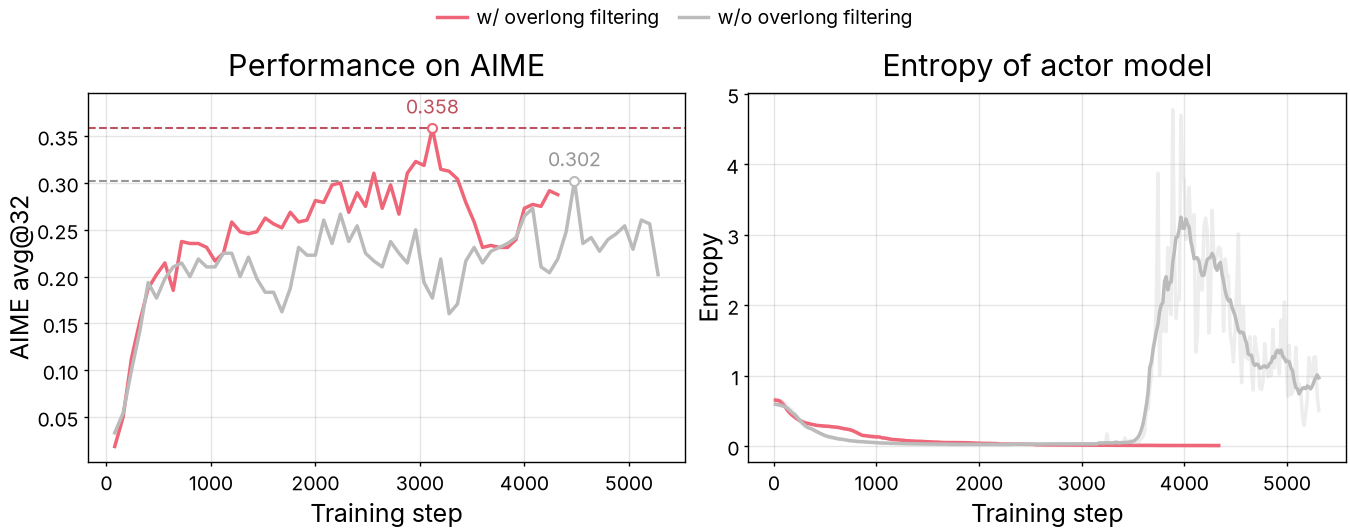

In [6]:
data = json.load(open("../dapo.json"))

fig, axes = plt.subplots(1, 2, figsize=(6.75, 2.5))
for name, color in [("w/ overlong filtering", colors["series-2"]), ("w/o overlong filtering", colors["neutral"])]:
    acc = data["fig5a"][name]
    axes[0].plot(acc["step"], acc["value"], color=color, label=name)
    best = max(acc["value"])
    mark_value(axes[0], acc["step"][acc["value"].index(best)], best, f"{best:.3f}", color)

    entropy = data["fig5b"][name]
    axes[1].plot(entropy["step"], entropy["value"], color=color, alpha=0.25)
    axes[1].plot(entropy["step"], smooth(entropy["value"]), color=color)

axes[0].set_title("Performance on AIME")
axes[0].set_ylabel("AIME avg@32")
axes[1].set_title("Entropy of actor model")
axes[1].set_ylabel("Entropy")
for ax in axes:
    ax.set_xlabel("Training step")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside upper center", ncol=2, frameon=False, borderaxespad=0)

fit_height(fig, axes, aspect=0.618)
fig.savefig("fig5.pdf")
fig.savefig("fig5.png")
plt.show()

## fig6

**Figure 6: AIME avg@32 over training before and after applying dynamic sampling on a baseline setting.** Dashed lines mark each run's best score. With dynamic sampling the run reaches its best of 0.438 at step 2,320, while without it the best is 0.421 at step 6,080, about 2.6× more steps.

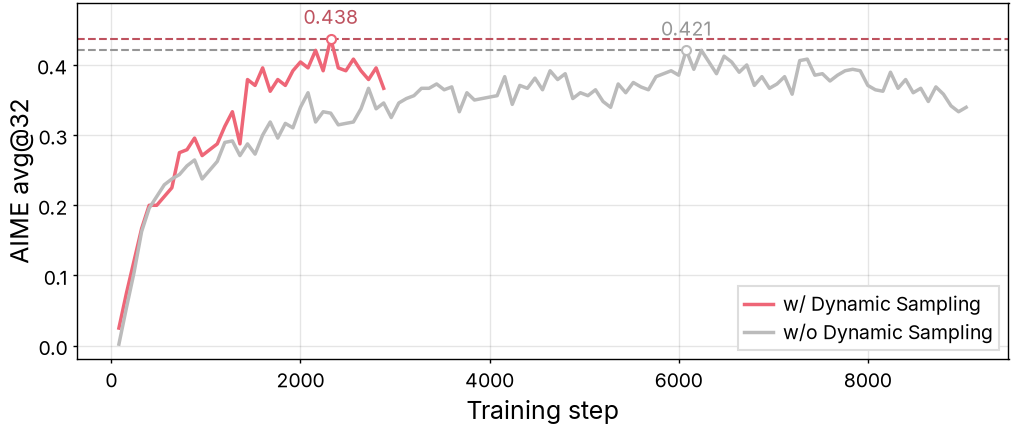

In [7]:
data = json.load(open("../dapo.json"))["fig6"]

fig, ax = plt.subplots(figsize=(5.0625, 2))
for name, color in [("w/ Dynamic Sampling", colors["series-2"]), ("w/o Dynamic Sampling", colors["neutral"])]:
    acc = data[name]
    ax.plot(acc["step"], acc["value"], color=color, label=name)
    best = max(acc["value"])
    mark_value(ax, acc["step"][acc["value"].index(best)], best, f"{best:.3f}", color)
ax.set_xlabel("Training step")
ax.set_ylabel("AIME avg@32")
ax.legend(loc="lower right")

fit_height(fig, ax, aspect=0.382)
fig.savefig("fig6.pdf")
fig.savefig("fig6.png")
plt.show()

## fig7

**Figure 7: Training dynamics of DAPO.** Panels show the mean response length, the reward score, the generation entropy and the mean token probability; curves are smoothed with a moving average over 5% of the steps; faint lines show raw values. Over training the mean response length grows from 655 to 4.6k tokens and the reward rises from −0.71 to 0.37, while entropy stays between 0.32 and 0.62 and mean probability between 0.74 and 0.86.

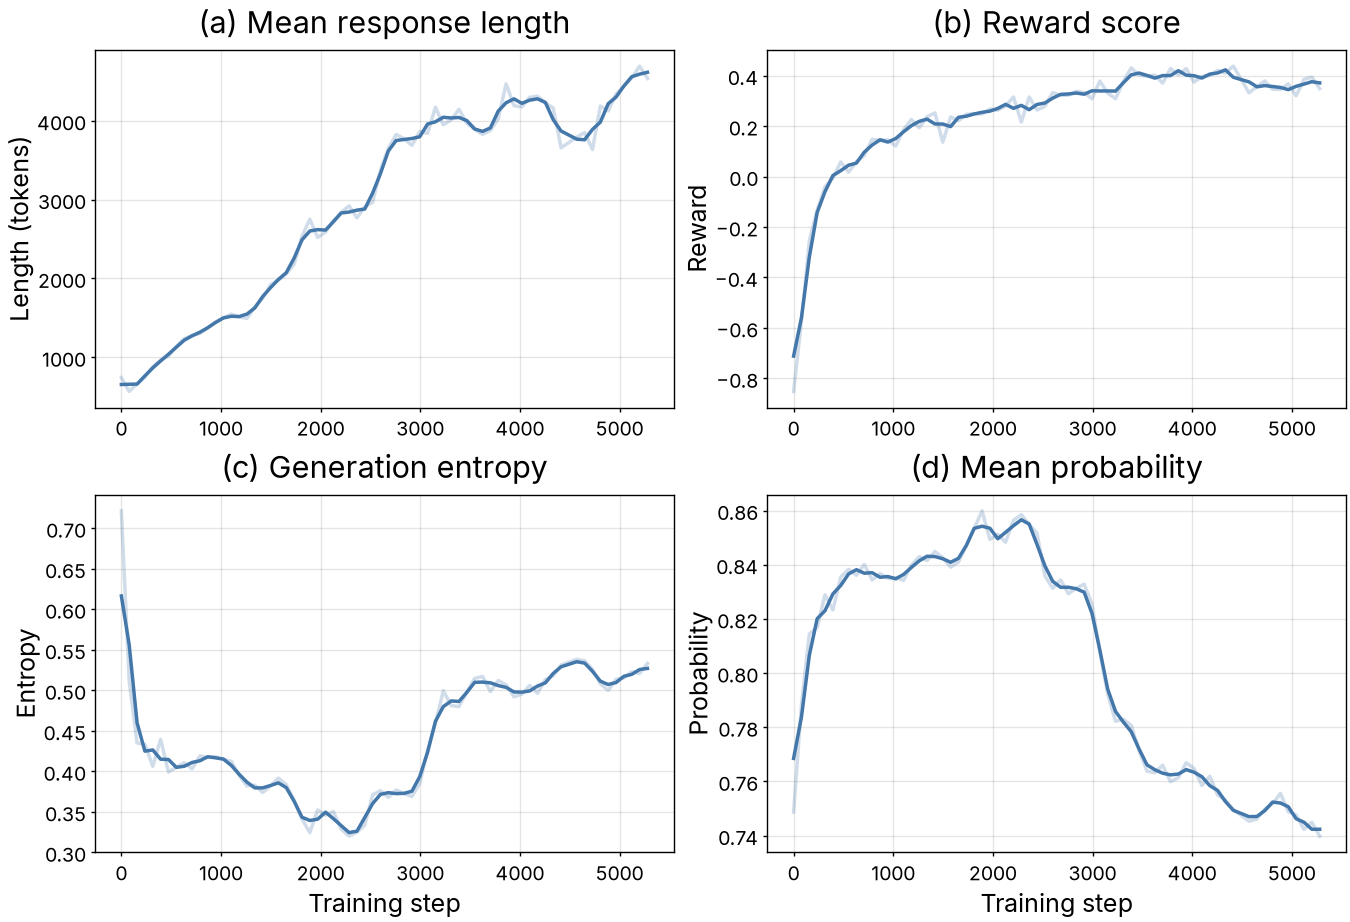

In [8]:
data = json.load(open("../dapo.json"))

fig, axes = plt.subplots(2, 2, figsize=(6.75, 4), sharex=True)
panels = [
    ("fig7a", "(a) Mean response length", "Length (tokens)"),
    ("fig7b", "(b) Reward score", "Reward"),
    ("fig7c", "(c) Generation entropy", "Entropy"),
    ("fig7d", "(d) Mean probability", "Probability"),
]
for ax, (key, title, ylabel) in zip(axes.flat, panels):
    ax.plot(data[key]["step"], data[key]["value"], color=colors["series-1"], alpha=0.25)
    ax.plot(data[key]["step"], smooth(data[key]["value"]), color=colors["series-1"])
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.tick_params(labelbottom=True)
for ax in axes[1]:
    ax.set_xlabel("Training step")

fit_height(fig, axes, aspect=0.618)
fig.savefig("fig7.pdf")
fig.savefig("fig7.png")
plt.show()